In [23]:
import torch 
import copy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torch import nn

In [24]:
# SGD vs IDBD: build the experiment yourself.
# Import torch, plotting tools, and your optimizer from idbd_exercise.py.
# Choose a seed, number of observations, initial learning rate, and meta-rate.
# Use half-squared error throughout: loss = 0.5 * (prediction - target)^2.

seed = 1234
num_observations = 500
initial_lr = 0.01
meta_lr = 0.1
loss_fn = lambda y, y_hat : 1/2 * (y - y_hat).square()

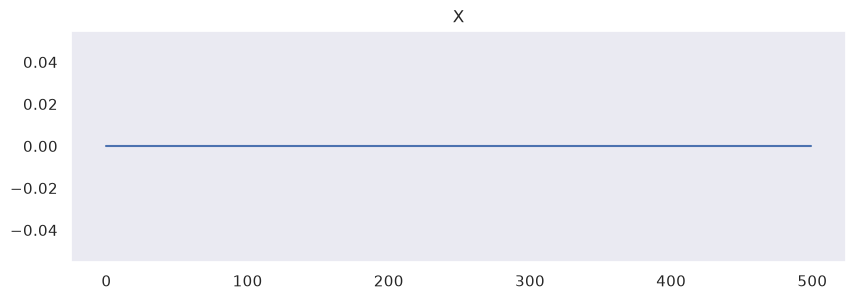

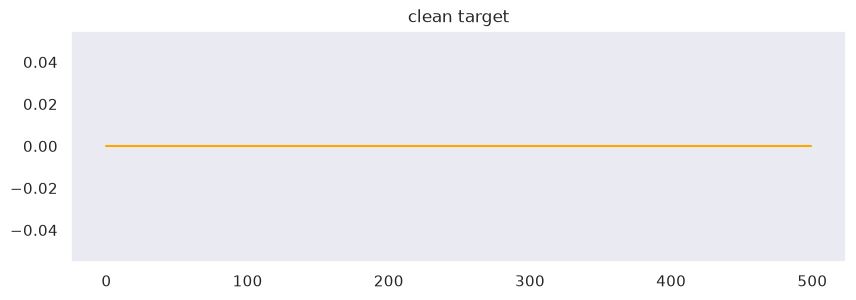

In [25]:
# Sample one binary feature: x[0] is 1 with probability 0.01, otherwise 0.
# Set clean_target = x[0]. Plot 500 observations and their targets.

X = np.random.binomial(1, 0.01, size=num_observations)
Y = X.copy()
sns.set_theme(style = "dark", rc={"figure.figsize" : (10, 3)})
sns.lineplot(X)
plt.title("X")
plt.show()
sns.lineplot(Y, color="orange")
plt.title("clean target")
plt.show()
# What weight would make a bias-free linear predictor exact?


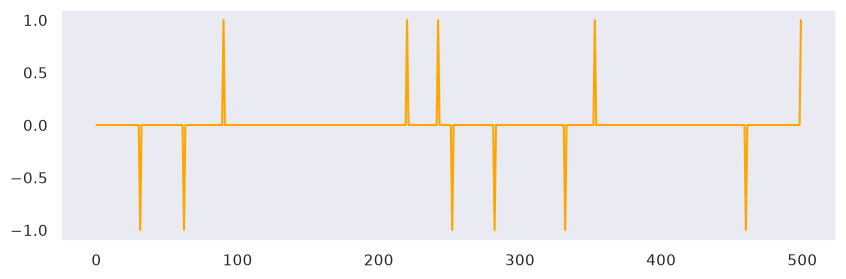

In [26]:
# Add an independent +1 or -1 to the target with probability 0.01.

Y += np.random.binomial(1, 0.01, size=num_observations) - np.random.binomial(1, 0.01, size=num_observations)
sns.lineplot(Y, color="orange")
plt.show()
# Then add independent Gaussian noise: mean 0, variance 5 (std = sqrt(5)).
# Add 4095 independent Bernoulli(0.01) distractors: 4096 features total.
x = np.random.binomial(1, 0.01, size=4096)
# Target depends only on x[0]; keep clean_target separately for evaluation.


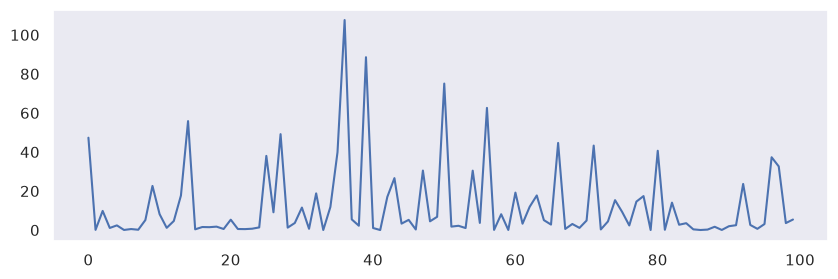

In [27]:
# Build Linear(4096, 1, bias=False); initialize all weights to zero.
# Use plain SGD: fixed learning rate, no momentum or weight decay.
input_dim = 2
output_dim = 1
model = nn.Linear(input_dim, 1, bias=False)
nn.init.zeros_(model.weight)

optim = torch.optim.SGD(params=model.parameters(), lr=initial_lr)

NUM_STEPS = 100
loss_list = []

for step in range(NUM_STEPS):
    x = np.random.binomial(1, 0.01, size=input_dim)
    y = x[0] + np.random.binomial(1, 0.01) * -np.random.randint(2) + np.random.normal(0, 5)
    x, y = torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

    optim.zero_grad()
    y_hat = model(x)
    loss = loss_fn(y, y_hat)
    loss_list.append(loss.item())
    loss.backward()
    optim.step()

sns.lineplot(loss_list)
plt.show()

# Each step: sample x and target -> zero gradients -> predict -> record prediction.
# Then compute half-squared error -> backward -> optimizer step.
# Use one new observation per update, not repeated passes over a dataset.


tensor([0., 0.])


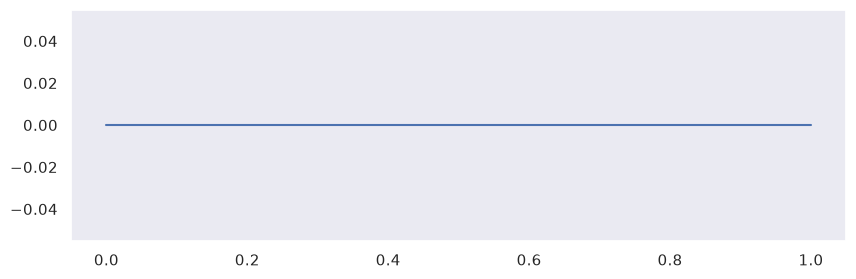

In [28]:
# Hand-check one update: delta = target - prediction; gradient = -delta*x.
# Plain SGD: weight <- weight + learning_rate * delta * x.
# Inspect weight.grad and the before/after weights for one observation.
# Why do active distractors get updated even when the error is pure noise?

with torch.no_grad():
    y_hat = model(x)
    delta = y - y_hat
    grad  = -delta*x

    print(grad)
    sns.lineplot(grad.numpy())
    plt.show()

In [29]:
from typing import Any

from torch.utils.data import IterableDataset

class DataStream(IterableDataset):
    def __init__(self, input_dim=4096, sample_fn=None, seed=1234):
        super().__init__()
        self.input_dim = input_dim
        self.rng = np.random.default_rng(seed)
        self.sample_fn = (
            self._sample_fn if sample_fn is None else sample_fn
        )

    @staticmethod
    def _sample_fn(rng, input_dim):
        x = rng.binomial(1, 0.01, size=input_dim).astype(np.float32)
        clean_y = float(x[0])

        impulse = (
            rng.choice([-1, 1])
            if rng.random() < 0.01
            else 0
        )
        noise = rng.normal(0, np.sqrt(5))
        noisy_y = clean_y + impulse + noise

        return (
            torch.from_numpy(x),
            torch.tensor(noisy_y, dtype=torch.float32),
            torch.tensor(clean_y, dtype=torch.float32),
        )

    def __iter__(self):
        while True:
            yield self.sample_fn(self.rng, self.input_dim)

In [30]:
# Follow the commented pseudocode in idbd_exercise.py to implement IDBD.
# Check two updates on a one-weight example before scaling up.

from idbd_exercise import IDBD

model = nn.Linear(1, 1, bias=False)
nn.init.constant_(model.weight, 0.5)


optimizers = {
    "IDBD" : {
        "takes_input" : True,
        "optim" : IDBD(
            params=model.parameters(),
            meta_lr=meta_lr,
            initial_lr=initial_lr
        )
    },
    "SGD" : {
        "takes_input" : False,
        "optim" : torch.optim.SGD(
            params=model.parameters(),
            lr=meta_lr
        )
    }
}

optimizer = optimizers["SGD"]
optim = optimizer["optim"]

for step in range(2):
    weight_before = model.weight.detach().item()
    x = torch.ones(1)
    y = torch.ones(1)

    optim.zero_grad()

    y_hat = model(x)
    loss = loss_fn(y, y_hat)
    loss.backward()

    print(
        f"step {step}\n"
        f"input/target: {x.item()}/{y.item()}\n"
        f"output: {y_hat.detach().item()}\n"
        f"loss: {loss.item()}\n"
        f"grad: {model.weight.grad.item()}\n"
    )

    optim.step(x if optimizer["takes_input"] else None)
    print(f"weight before: {weight_before} and after update: {model.weight.detach().item()}\n")

# Check that meta-rate zero recovers SGD with the same loss and learning rate.
# Explain the roles of beta, alpha, and h in your own words.


step 0
input/target: 1.0/1.0
output: 0.5
loss: 0.125
grad: -0.5

weight before: 0.5 and after update: 0.550000011920929

step 1
input/target: 1.0/1.0
output: 0.550000011920929
loss: 0.10124999284744263
grad: -0.44999998807907104

weight before: 0.550000011920929 and after update: 0.5950000286102295



In [38]:
from collections import deque
from itertools import islice

from torch.utils.data import DataLoader
from idbd_exercise import IDBD

input_dim = 16
BATCH_SIZE = 32
TRAINING_ITERATIONS = 2**15


def _metric_totals():
    return dict(examples=0, active_examples=0, noisy_sse=0.0,
                clean_sse=0.0, active_clean_sse=0.0)


def _accumulate_metrics(totals, prediction, noisy_y, clean_y):
    prediction = prediction.detach().double()
    noisy_error = prediction - noisy_y.double()
    clean_error = prediction - clean_y.double()
    active = clean_y == 1
    totals["examples"] += clean_y.numel()
    totals["active_examples"] += active.sum().item()
    totals["noisy_sse"] += noisy_error.square().sum().item()
    totals["clean_sse"] += clean_error.square().sum().item()
    totals["active_clean_sse"] += clean_error[active].square().sum().item()


def _summarize_metrics(totals_by_model):
    rows = []
    for name, totals in totals_by_model.items():
        count = totals["examples"]
        if count == 0:
            raise ValueError("The data stream produced no examples")
        active_count = totals["active_examples"]
        noisy_mse = totals["noisy_sse"] / count
        rows.append({
            "model": name,
            "examples": count,
            "active_examples": active_count,
            "half_squared_loss": 0.5 * noisy_mse,
            "noisy_mse": noisy_mse,
            "clean_mse": totals["clean_sse"] / count,
            "active_clean_mse": (
                totals["active_clean_sse"] / active_count
                if active_count else float("nan")
            ),
        })
    return pd.DataFrame(rows).set_index("model")


def train(dataset, iterations, batch_size, initial_lr, meta_lr):
    print(dataset.input_dim)

    idbd_model = nn.Linear(dataset.input_dim, 1, bias=False).train(True)
    sgd_model = copy.deepcopy(idbd_model)

    models = {
        "IDBD": idbd_model,
        "SGD": sgd_model,
    }


    optimizers = {
        "IDBD": IDBD(models["IDBD"].parameters(),
                     initial_lr=initial_lr, meta_lr=meta_lr),
        "SGD": torch.optim.SGD(models["SGD"].parameters(), lr=initial_lr),
    }
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=0)
    totals = {name: _metric_totals() for name in (*models, "Zero")}
    history = []
    last_predictions = deque(maxlen=500)
    examples_seen = 0
    next_report = 1

    for step, (x, noisy_y, clean_y) in enumerate(islice(loader, iterations), start=1):
        predictions = {}
        for name, model in models.items():
            optimizer = optimizers[name]
            optimizer.zero_grad(set_to_none=True)
            prediction = model(x).squeeze(-1)
            loss = 0.5 * (prediction - noisy_y).square().mean()

            if not torch.isfinite(loss).item:
                raise FloatingPointError(f"{name}: non-finite loss at update {step}")

            predictions[name] = prediction.detach().clone()
            _accumulate_metrics(totals[name], prediction, noisy_y, clean_y)
            loss.backward()

            optimizer.step(x if name == "IDBD" else None)

            with torch.no_grad(): # sanity check on parameters
                weights = model.weight.squeeze(0)
                if name == "IDBD":
                    state = optimizer.state[model.weight]
                    rates = state["beta"].exp().squeeze(0)
                    finite_state = torch.isfinite(state["h"]).all()
                else:
                    rates = torch.full_like(weights, initial_lr)
                    finite_state = True
                if not (torch.isfinite(weights).all()
                        and torch.isfinite(rates).all() and finite_state):
                    raise FloatingPointError(
                        f"{name}: non-finite optimizer state at update {step}"
                    )

            with torch.no_grad():
                history.append({
                    "model": name, "update": step,
                    "examples": examples_seen + len(x),
                    "loss": loss.item(),
                    "useful_weight": weights[0].item(),
                    "distractor_weight_rms": weights[1:].square().mean().sqrt().item(),
                    "useful_lr": rates[0].item(),
                    "distractor_lr_mean": rates[1:].mean().item(),
                })
            progress = step / iterations * 100

            if progress >= next_report:
                last_run = history[-1]
                print(
                    f"training {progress:.0f}% done\n"
                    f"model: {last_run['model']}\n"
                    f"examples seen: {last_run['examples']}\n"
                    f"loss: {last_run['loss']:.4f}\n"
                    f"useful weight: {last_run['useful_weight']:.4f}\n"
                    f"rms of distractor weight: {weights[1:].square().mean().sqrt().item()}\n"
                    f"mean lr of distractor weights: {last_run['distractor_lr_mean']:.6f}\n"
                )
                next_report = (int(progress) // 10 + 1) * 10

        _accumulate_metrics(totals["Zero"], torch.zeros_like(clean_y), noisy_y, clean_y)
        for i in range(len(x)):
            last_predictions.append({
                "example": examples_seen + i + 1,
                "clean_target": clean_y[i].item(),
                "noisy_target": noisy_y[i].item(),
                **{name: prediction[i].item() for name, prediction in predictions.items()},
            })
        examples_seen += len(x)

    return (models, pd.DataFrame(history), _summarize_metrics(totals),
            pd.DataFrame(last_predictions))

train_stream = DataStream(input_dim=input_dim, seed=seed)
models, train_history, train_metrics, final_predictions = train(
    train_stream, iterations=TRAINING_ITERATIONS, batch_size=BATCH_SIZE,
    initial_lr=initial_lr, meta_lr=meta_lr,
)
idbd_model, sgd_model = models["IDBD"], models["SGD"]
print("Training metrics (predictions before each update):")
print(train_metrics.to_string())

16
training 1% done
model: IDBD
examples seen: 10496
loss: 2.2146
useful weight: -0.0759
rms of distractor weight: 0.16547340154647827
mean lr of distractor weights: 0.010002

training 10% done
model: IDBD
examples seen: 104864
loss: 2.9256
useful weight: 0.3392
rms of distractor weight: 0.13446010649204254
mean lr of distractor weights: 0.010077

training 20% done
model: IDBD
examples seen: 209728
loss: 2.6316
useful weight: 0.6182
rms of distractor weight: 0.09522785246372223
mean lr of distractor weights: 0.010226

training 30% done
model: IDBD
examples seen: 314592
loss: 2.3759
useful weight: 0.8664
rms of distractor weight: 0.07033022493124008
mean lr of distractor weights: 0.010355

training 40% done
model: IDBD
examples seen: 419456
loss: 3.4452
useful weight: 1.0599
rms of distractor weight: 0.055743515491485596
mean lr of distractor weights: 0.010444

training 50% done
model: IDBD
examples seen: 524288
loss: 3.0999
useful weight: 1.0413
rms of distractor weight: 0.040848281234

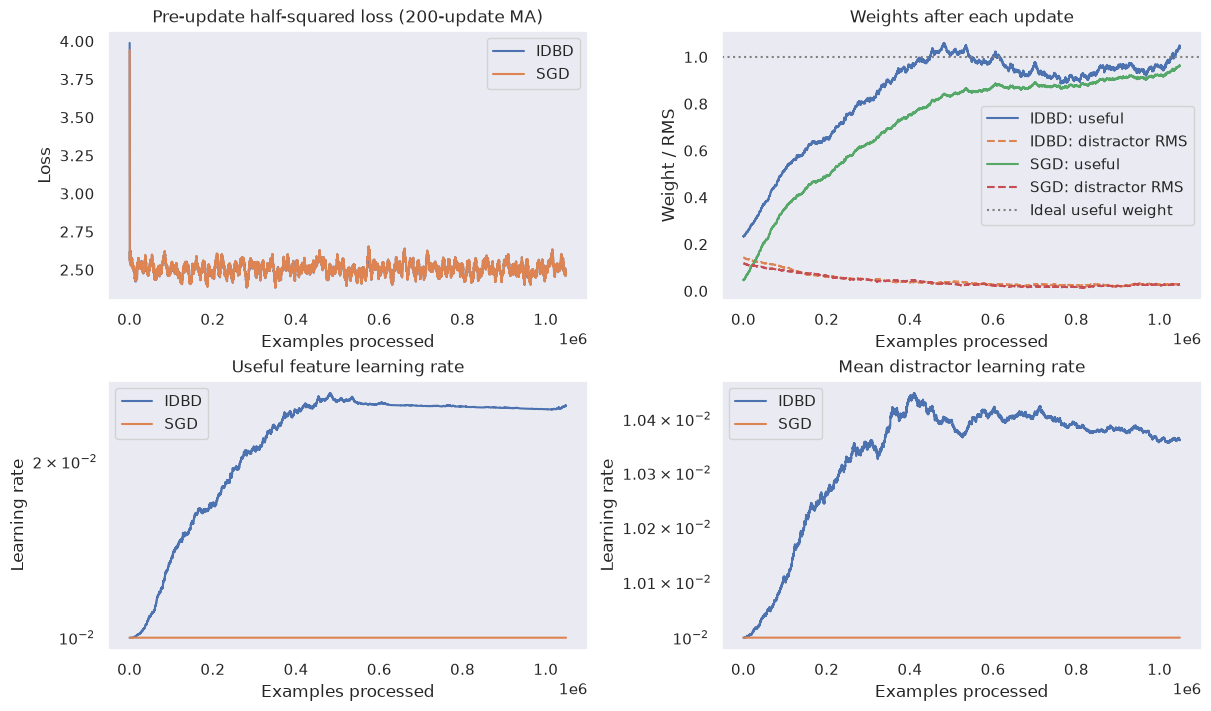

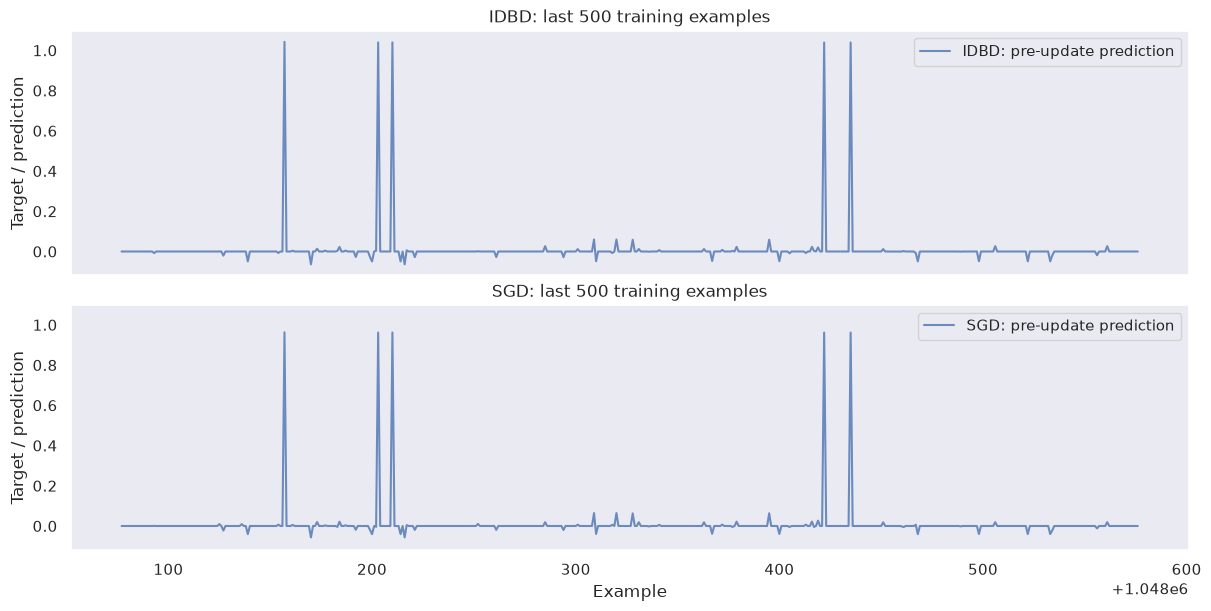

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for name in models:

    run = train_history[train_history["model"] == name]
    axes[0, 0].plot(run["examples"], run["loss"].rolling(200, min_periods=1).mean(),
                    label=name)
    axes[0, 1].plot(run["examples"], run["useful_weight"], label=f"{name}: useful")
    axes[0, 1].plot(run["examples"], run["distractor_weight_rms"],
                    linestyle="--", label=f"{name}: distractor RMS")
    axes[1, 0].plot(run["examples"], run["useful_lr"], label=name)
    axes[1, 1].plot(run["examples"], run["distractor_lr_mean"], label=name)
axes[0, 0].set_title("Pre-update half-squared loss (200-update MA)")
axes[0, 0].set_ylabel("Loss")
axes[0, 1].set_title("Weights after each update")
axes[0, 1].set_ylabel("Weight / RMS")
axes[0, 1].axhline(1, color="gray", linestyle=":", label="Ideal useful weight")
axes[1, 0].set_title("Useful feature learning rate")
axes[1, 1].set_title("Mean distractor learning rate")
for ax in axes[1]:
    ax.set_yscale("log")
    ax.set_ylabel("Learning rate")
for ax in axes.flat:
    ax.set_xlabel("Examples processed")
    ax.legend()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, name in zip(axes, models):
    #ax.plot(final_predictions["example"], final_predictions["clean_target"],color="black", label="Clean target")
    ax.plot(final_predictions["example"], final_predictions[name], alpha=0.8, label=f"{name}: pre-update prediction")
    ax.set_title(f"{name}: last {len(final_predictions)} training examples")
    ax.set_ylabel("Target / prediction")
    ax.legend()
axes[-1].set_xlabel("Example")
plt.show()


Test metrics (independent stream, no updates):
       examples  active_examples  half_squared_loss  noisy_mse  clean_mse  active_clean_mse  distractor_weight_rms
model                                                                                                             
IDBD      12800              123           2.498811   4.997622   0.000146          0.001496               0.029325
SGD       12800              123           2.498710   4.997421   0.000132          0.001569               0.027365
Zero      12800              123           2.501393   5.002787   0.009609          1.000000               0.000000
Expected clean MSE of the zero predictor: 0.01; active-only MSE: 1.0


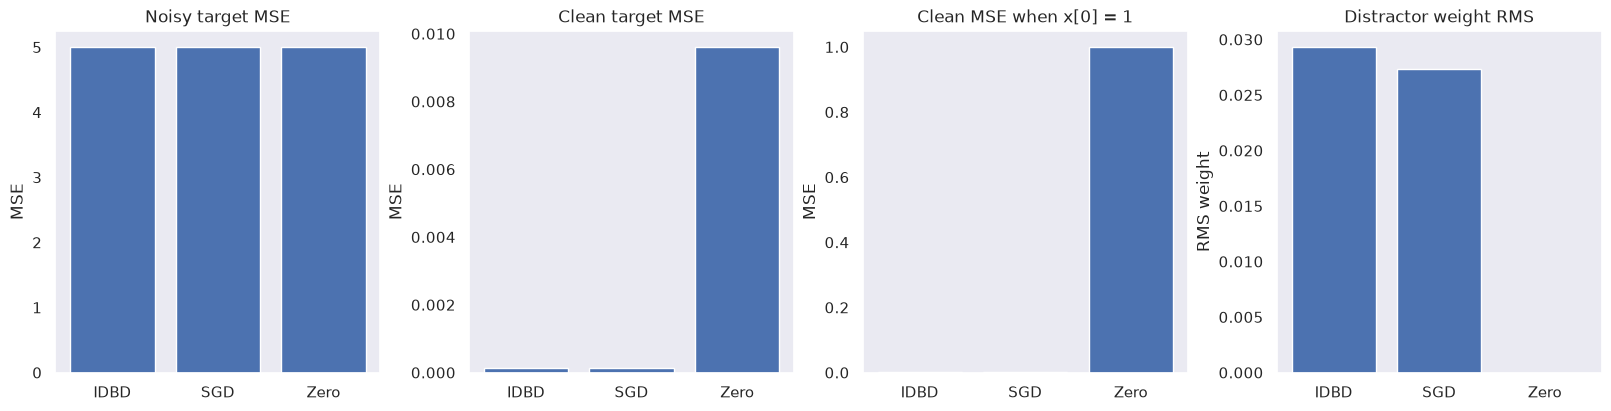

In [36]:
# Evaluate both frozen models on identical, independently generated examples.
# MSE is twice the half-squared loss used for training.
TEST_ITERATIONS = 100
TEST_BATCH_SIZE = 128
TEST_SEED = seed + 1


@torch.no_grad()
def test(models, dataset, iterations, batch_size):
    totals = {name: _metric_totals() for name in (*models, "Zero")}
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=0)
    training_modes = {name: model.training for name, model in models.items()}

    try:
        for model in models.values():
            model.eval()
        for x, noisy_y, clean_y in islice(loader, iterations):
            for name, model in models.items():
                prediction = model(x).squeeze(-1)
                if not torch.isfinite(prediction).all().item():
                    raise FloatingPointError(f"{name}: non-finite test prediction")
                _accumulate_metrics(totals[name], prediction, noisy_y, clean_y)
            _accumulate_metrics(totals["Zero"], torch.zeros_like(clean_y), noisy_y, clean_y)
    finally:
        for name, model in models.items():
            model.train(training_modes[name])
    metrics = _summarize_metrics(totals)
    # Feature 0 is useful; all remaining weights belong to distractors.
    metrics["distractor_weight_rms"] = [
        model.weight[:, 1:].square().mean().sqrt().item()
        for model in models.values()
    ] + [0.0]  # The zero predictor has only zero weights.
    return metrics


test_stream = DataStream(input_dim=input_dim, seed=TEST_SEED)
test_metrics = test(models, test_stream, iterations=TEST_ITERATIONS,
                    batch_size=TEST_BATCH_SIZE)
print("Test metrics (independent stream, no updates):")
print(test_metrics.to_string())
print("Expected clean MSE of the zero predictor: 0.01; active-only MSE: 1.0")

fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)
for ax, column, title in zip(
    axes, ("noisy_mse", "clean_mse", "active_clean_mse", "distractor_weight_rms"),
    ("Noisy target MSE", "Clean target MSE", "Clean MSE when x[0] = 1", "Distractor weight RMS"),
):
    ax.bar(test_metrics.index, test_metrics[column])
    ax.set_title(title)
    ax.set_ylabel("RMS weight" if column == "distractor_weight_rms" else "MSE")
plt.show()

# For multiple seeds/rates, repeat train/test with fresh DataStream instances
# and record the configuration and test metrics for every run.
